# Cryptocurrency Volatility: Feature Engineering

This notebook develops and evaluates candidate features for forecasting cryptocurrency volatility.

The feature-engineering process follows strict time-series principles:

- features must use information available at prediction time;
- future observations must never enter predictor calculations;
- rolling statistics must be constructed chronologically;
- preprocessing parameters must later be estimated using training data only;
- candidate features are evaluated experimentally before being moved into the reusable feature pipeline.

The primary candidate forecasting target is next-day log Garman–Klass volatility.
The target choice will remain subject to empirical model validation rather than being assumed optimal in advance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
INTERIM_DIR = Path("../data/interim")

FILES = {
    "BTC": INTERIM_DIR / "btcusdt_1d_clean.parquet",
    "ETH": INTERIM_DIR / "ethusdt_1d_clean.parquet",
    "SOL": INTERIM_DIR / "solusdt_1d_clean.parquet",
    "BNB": INTERIM_DIR / "bnbusdt_1d_clean.parquet",
}

TRADING_DAYS = 365

In [3]:
data = {
    asset: pd.read_parquet(path)
    for asset, path in FILES.items()
}

In [4]:
for asset, df in data.items():
    print(
        asset,
        df.shape,
        df["timestamp"].min(),
        df["timestamp"].max(),
    )

BTC (2105, 11) 2021-01-01 00:00:00+00:00 2026-10-06 00:00:00+00:00
ETH (2105, 11) 2021-01-01 00:00:00+00:00 2026-10-06 00:00:00+00:00
SOL (2105, 11) 2021-01-01 00:00:00+00:00 2026-10-06 00:00:00+00:00
BNB (2105, 11) 2021-01-01 00:00:00+00:00 2026-10-06 00:00:00+00:00


In [ ]:
for _asset, df in data.items():
    log_hl = np.log(
        df["high"] / df["low"]
    )

    log_co = np.log(
        df["close"] / df["open"]
    )

    df["gk_variance"] = (
        0.5 * log_hl.pow(2)
        - (2 * np.log(2) - 1)
        * log_co.pow(2)
    )

    df["gk_volatility"] = np.sqrt(
        df["gk_variance"].clip(lower=0)
    )

    df["log_gk_volatility"] = np.log(
        df["gk_volatility"].clip(
            lower=1e-8
        )
    )

In [6]:
for asset, df in data.items():
    print(
        asset,
        "| min:",
        df["log_gk_volatility"].min(),
        "| max:",
        df["log_gk_volatility"].max(),
        "| missing:",
        df["log_gk_volatility"].isna().sum(),
    )

BTC | min: -6.033992630507238 | max: -1.402951358982811 | missing: 0
ETH | min: -5.806241675880595 | max: -0.9848249560817682 | missing: 0
SOL | min: -5.047608215118294 | max: -0.7631210724792028 | missing: 0
BNB | min: -5.543909730342488 | max: -1.058656200268594 | missing: 0


In [ ]:
for _asset, df in data.items():
    df["target_log_gk_vol_t_plus_1"] = (
        df["log_gk_volatility"]
        .shift(-1)
    )

In [8]:
data["BTC"][
    [
        "timestamp",
        "log_gk_volatility",
        "target_log_gk_vol_t_plus_1",
    ]
].head(10)

,timestamp,log_gk_volatility,target_log_gk_vol_t_plus_1
0,2021-01-01 00:00:00+00:00,-3.815056,-2.517910
1,2021-01-02 00:00:00+00:00,-2.517910,-2.854540
2,2021-01-03 00:00:00+00:00,-2.854540,-2.086288
3,2021-01-04 00:00:00+00:00,-2.086288,-2.395774
4,2021-01-05 00:00:00+00:00,-2.395774,-2.911848
5,2021-01-06 00:00:00+00:00,-2.911848,-2.793680
6,2021-01-07 00:00:00+00:00,-2.793680,-2.335430
7,2021-01-08 00:00:00+00:00,-2.335430,-3.071568
8,2021-01-09 00:00:00+00:00,-3.071568,-2.193965
9,2021-01-10 00:00:00+00:00,-2.193965,-1.861449


In [9]:
for asset, df in data.items():
    expected = (
        df["log_gk_volatility"]
        .shift(-1)
    )

    matches = (
        df["target_log_gk_vol_t_plus_1"]
        .equals(expected)
    )

    print(
        f"{asset}: target alignment correct = {matches}"
    )

BTC: target alignment correct = True
ETH: target alignment correct = True
SOL: target alignment correct = True
BNB: target alignment correct = True


In [10]:
for asset, df in data.items():
    print(
        asset,
        "| target missing values:",
        df[
            "target_log_gk_vol_t_plus_1"
        ].isna().sum(),
    )

BTC | target missing values: 1
ETH | target missing values: 1
SOL | target missing values: 1
BNB | target missing values: 1


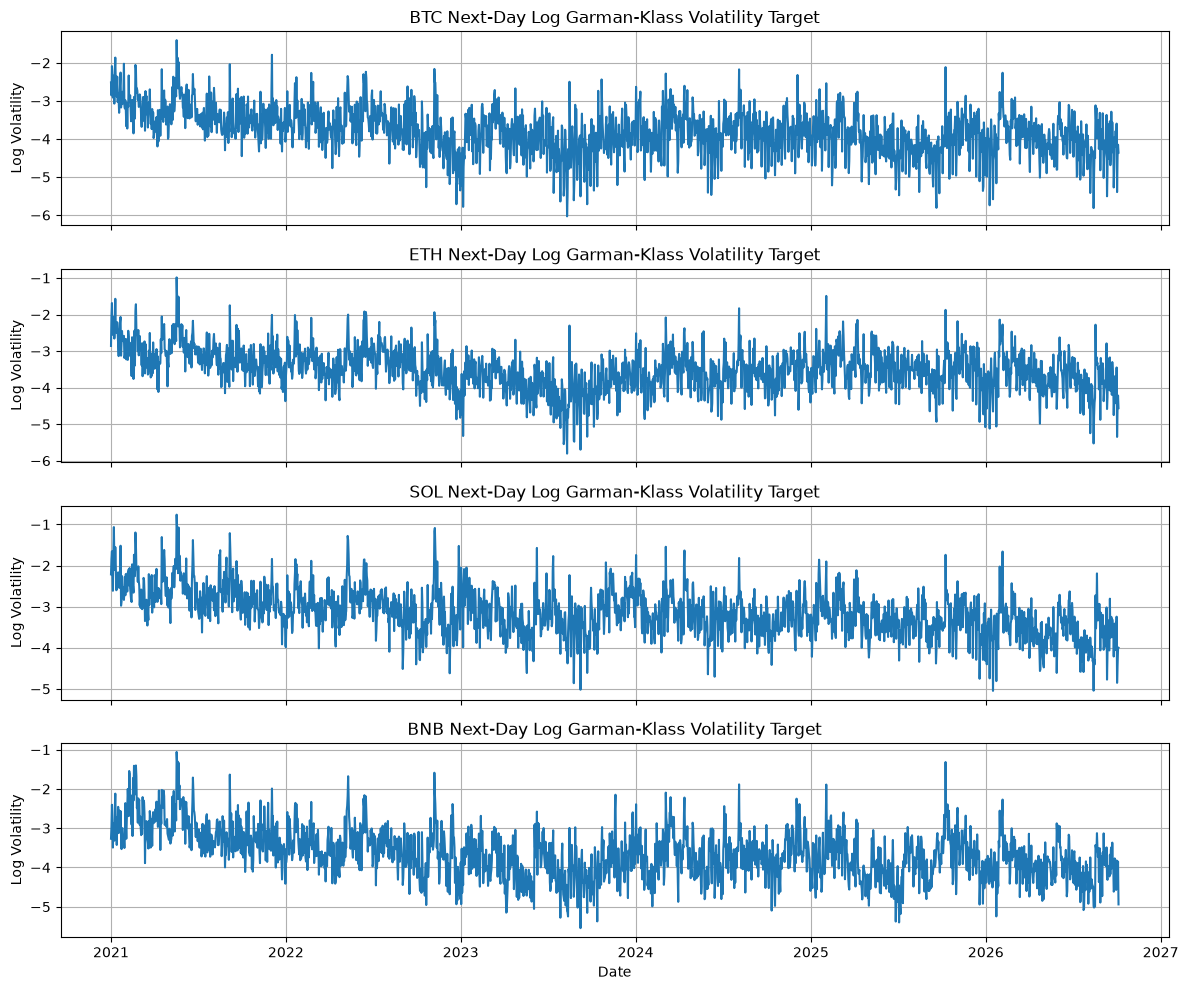

In [11]:
fig, axes = plt.subplots(
    4,
    1,
    figsize=(12, 10),
    sharex=True,
)

for ax, (asset, df) in zip(
    axes,
    data.items(),
    strict=True,
):
    ax.plot(
        df["timestamp"],
        df["target_log_gk_vol_t_plus_1"],
    )

    ax.set_title(
        f"{asset} Next-Day Log Garman-Klass Volatility Target"
    )

    ax.set_ylabel(
        "Log Volatility"
    )

    ax.grid(True)

axes[-1].set_xlabel(
    "Date"
)

plt.tight_layout()
plt.show()

## Forecasting Target

The primary candidate forecasting target is next-day log Garman–Klass volatility.

For each observation at time \(t\), predictor variables will be constructed using only information available at or before time \(t\). The target is the log Garman–Klass volatility observed at time \(t+1\).

Formally:

\[
y_{t+1} = \log(\sigma^{GK}_{t+1})
\]

This one-step-ahead formulation ensures that the model is evaluated as a genuine forecasting system rather than using contemporaneous or future information.

The final observation for each asset has no observable \(t+1\) target within the sample and is therefore expected to contain a missing target value. Such rows will later be removed when constructing the model-ready supervised dataset.

## Lagged Return and Volatility Features

The first candidate predictors are lagged market variables.

Lagged features allow the model to use recent historical information without accessing future observations.

We begin with:

- current-day log return;
- lagged log returns;
- current-day log Garman–Klass volatility;
- lagged log Garman–Klass volatility.

These features are motivated by the earlier EDA, which showed relatively weak return autocorrelation but strong volatility persistence.

In [ ]:
for _asset, df in data.items():
    df["log_return"] = np.log(
        df["close"] / df["close"].shift(1)
    )

    df["log_return_lag_1"] = (
        df["log_return"].shift(1)
    )

    df["log_return_lag_2"] = (
        df["log_return"].shift(2)
    )

    df["log_return_lag_3"] = (
        df["log_return"].shift(3)
    )

    df["log_gk_volatility_lag_1"] = (
        df["log_gk_volatility"].shift(1)
    )

    df["log_gk_volatility_lag_2"] = (
        df["log_gk_volatility"].shift(2)
    )

    df["log_gk_volatility_lag_3"] = (
        df["log_gk_volatility"].shift(3)
    )

In [13]:
data["BTC"][
    [
        "timestamp",
        "log_return",
        "log_return_lag_1",
        "log_return_lag_2",
        "log_gk_volatility",
        "log_gk_volatility_lag_1",
        "log_gk_volatility_lag_2",
        "target_log_gk_vol_t_plus_1",
    ]
].head(10)

,timestamp,log_return,log_return_lag_1,log_return_lag_2,log_gk_volatility,log_gk_volatility_lag_1,log_gk_volatility_lag_2,target_log_gk_vol_t_plus_1
0,2021-01-01 00:00:00+00:00,NaN,NaN,NaN,-3.815056,NaN,NaN,-2.517910
1,2021-01-02 00:00:00+00:00,0.092625,NaN,NaN,-2.517910,-3.815056,NaN,-2.854540
2,2021-01-03 00:00:00+00:00,0.025216,0.092625,NaN,-2.854540,-2.517910,-3.815056,-2.086288
3,2021-01-04 00:00:00+00:00,-0.031126,0.025216,0.092625,-2.086288,-2.854540,-2.517910,-2.395774
4,2021-01-05 00:00:00+00:00,0.059492,-0.031126,0.025216,-2.395774,-2.086288,-2.854540,-2.911848
5,2021-01-06 00:00:00+00:00,0.079790,0.059492,-0.031126,-2.911848,-2.395774,-2.086288,-2.793680
6,2021-01-07 00:00:00+00:00,0.069920,0.079790,0.059492,-2.793680,-2.911848,-2.395774,-2.335430
7,2021-01-08 00:00:00+00:00,0.028760,0.069920,0.079790,-2.335430,-2.793680,-2.911848,-3.071568
8,2021-01-09 00:00:00+00:00,-0.012262,0.028760,0.069920,-3.071568,-2.335430,-2.793680,-2.193965
9,2021-01-10 00:00:00+00:00,-0.049556,-0.012262,0.028760,-2.193965,-3.071568,-2.335430,-1.861449


In [14]:
for asset, df in data.items():
    return_lag_correct = (
        df["log_return_lag_1"]
        .equals(
            df["log_return"].shift(1)
        )
    )

    volatility_lag_correct = (
        df["log_gk_volatility_lag_1"]
        .equals(
            df["log_gk_volatility"].shift(1)
        )
    )

    print(
        asset,
        "| return lag correct:",
        return_lag_correct,
        "| volatility lag correct:",
        volatility_lag_correct,
    )

BTC | return lag correct: True | volatility lag correct: True
ETH | return lag correct: True | volatility lag correct: True
SOL | return lag correct: True | volatility lag correct: True
BNB | return lag correct: True | volatility lag correct: True


## HAR-Style Multi-Horizon Volatility Features

The EDA showed strong persistence in Garman–Klass volatility across multiple horizons.

Rather than supplying a large number of individual volatility lags, HAR-style features summarize volatility over economically meaningful horizons.

For daily cryptocurrency data, we consider:

- daily volatility: current-day log Garman–Klass volatility;
- weekly volatility: mean log volatility over the most recent 7 days;
- monthly volatility: mean log volatility over the most recent 30 days.

Because the forecasting decision is made after day \(t\) has closed, all observations up to and including day \(t\) are available when predicting day \(t+1\).

Therefore, rolling windows ending at day \(t\) do not introduce future information.

In [ ]:
for _asset, df in data.items():
    df["har_vol_daily"] = (
        df["log_gk_volatility"]
    )

    df["har_vol_weekly"] = (
        df["log_gk_volatility"]
        .rolling(
            window=7,
            min_periods=7,
        )
        .mean()
    )

    df["har_vol_monthly"] = (
        df["log_gk_volatility"]
        .rolling(
            window=30,
            min_periods=30,
        )
        .mean()
    )

In [16]:
data["BTC"][
    [
        "timestamp",
        "log_gk_volatility",
        "har_vol_daily",
        "har_vol_weekly",
        "har_vol_monthly",
        "target_log_gk_vol_t_plus_1",
    ]
].head(35)

,timestamp,log_gk_volatility,har_vol_daily,har_vol_weekly,har_vol_monthly,target_log_gk_vol_t_plus_1
0,2021-01-01 00:00:00+00:00,-3.815056,-3.815056,NaN,NaN,-2.517910
1,2021-01-02 00:00:00+00:00,-2.517910,-2.517910,NaN,NaN,-2.854540
2,2021-01-03 00:00:00+00:00,-2.854540,-2.854540,NaN,NaN,-2.086288
3,2021-01-04 00:00:00+00:00,-2.086288,-2.086288,NaN,NaN,-2.395774
4,2021-01-05 00:00:00+00:00,-2.395774,-2.395774,NaN,NaN,-2.911848
5,2021-01-06 00:00:00+00:00,-2.911848,-2.911848,NaN,NaN,-2.793680
6,2021-01-07 00:00:00+00:00,-2.793680,-2.793680,-2.767871,NaN,-2.335430
7,2021-01-08 00:00:00+00:00,-2.335430,-2.335430,-2.556496,NaN,-3.071568
8,2021-01-09 00:00:00+00:00,-3.071568,-3.071568,-2.635590,NaN,-2.193965
9,2021-01-10 00:00:00+00:00,-2.193965,-2.193965,-2.541222,NaN,-1.861449


In [17]:
btc = data["BTC"]

manual_weekly = (
    btc.loc[
        0:6,
        "log_gk_volatility",
    ].mean()
)

calculated_weekly = (
    btc.loc[
        6,
        "har_vol_weekly",
    ]
)

print(
    "Manual weekly:",
    manual_weekly,
)

print(
    "Calculated weekly:",
    calculated_weekly,
)

print(
    "Match:",
    np.isclose(
        manual_weekly,
        calculated_weekly,
    ),
)

Manual weekly: -2.767870798590249
Calculated weekly: -2.7678707985902493
Match: True


In [18]:
manual_monthly = (
    btc.loc[
        0:29,
        "log_gk_volatility",
    ].mean()
)

calculated_monthly = (
    btc.loc[
        29,
        "har_vol_monthly",
    ]
)

print(
    "Manual monthly:",
    manual_monthly,
)

print(
    "Calculated monthly:",
    calculated_monthly,
)

print(
    "Match:",
    np.isclose(
        manual_monthly,
        calculated_monthly,
    ),
)

Manual monthly: -2.7121969987711223
Calculated monthly: -2.7121969987711227
Match: True


In [19]:
for asset, df in data.items():
    expected_weekly = (
        df["log_gk_volatility"]
        .rolling(
            window=7,
            min_periods=7,
        )
        .mean()
    )

    expected_monthly = (
        df["log_gk_volatility"]
        .rolling(
            window=30,
            min_periods=30,
        )
        .mean()
    )

    weekly_correct = (
        df["har_vol_weekly"]
        .equals(expected_weekly)
    )

    monthly_correct = (
        df["har_vol_monthly"]
        .equals(expected_monthly)
    )

    print(
        asset,
        "| weekly correct:",
        weekly_correct,
        "| monthly correct:",
        monthly_correct,
    )

BTC | weekly correct: True | monthly correct: True
ETH | weekly correct: True | monthly correct: True
SOL | weekly correct: True | monthly correct: True
BNB | weekly correct: True | monthly correct: True


In [20]:
for asset, df in data.items():
    print(
        asset,
        "| weekly missing:",
        df["har_vol_weekly"].isna().sum(),
        "| monthly missing:",
        df["har_vol_monthly"].isna().sum(),
    )

BTC | weekly missing: 6 | monthly missing: 29
ETH | weekly missing: 6 | monthly missing: 29
SOL | weekly missing: 6 | monthly missing: 29
BNB | weekly missing: 6 | monthly missing: 29


## Return Magnitude and Downside-Shock Features

Raw returns contain directional information, but volatility is often more closely related to the magnitude of recent price movements.

We therefore evaluate:

- squared returns;
- absolute returns;
- a negative-return indicator;
- downside return magnitude.

These features are all constructed using information available at or before time \(t\), so they remain valid predictors for forecasting volatility at time \(t+1\).

In [ ]:
for _asset, df in data.items():
    df["squared_return"] = (
        df["log_return"].pow(2)
    )

    df["absolute_return"] = (
        df["log_return"].abs()
    )

    df["negative_return_indicator"] = (
        df["log_return"] < 0
    ).astype(int)

    df["downside_return"] = (
        df["log_return"]
        .clip(upper=0)
        .abs()
    )

In [23]:
data["BTC"][
    [
        "timestamp",
        "log_return",
        "squared_return",
        "absolute_return",
        "negative_return_indicator",
        "downside_return",
    ]
].head(15)

,timestamp,log_return,squared_return,absolute_return,negative_return_indicator,downside_return
0,2021-01-01 00:00:00+00:00,NaN,NaN,NaN,0,NaN
1,2021-01-02 00:00:00+00:00,0.092625,0.008579,0.092625,0,0.000000
2,2021-01-03 00:00:00+00:00,0.025216,0.000636,0.025216,0,0.000000
3,2021-01-04 00:00:00+00:00,-0.031126,0.000969,0.031126,1,0.031126
4,2021-01-05 00:00:00+00:00,0.059492,0.003539,0.059492,0,0.000000
5,2021-01-06 00:00:00+00:00,0.079790,0.006366,0.079790,0,0.000000
6,2021-01-07 00:00:00+00:00,0.069920,0.004889,0.069920,0,0.000000
7,2021-01-08 00:00:00+00:00,0.028760,0.000827,0.028760,0,0.000000
8,2021-01-09 00:00:00+00:00,-0.012262,0.000150,0.012262,1,0.012262
9,2021-01-10 00:00:00+00:00,-0.049556,0.002456,0.049556,1,0.049556


In [24]:
for asset, df in data.items():
    squared_correct = (
        df["squared_return"]
        .equals(
            df["log_return"].pow(2)
        )
    )

    absolute_correct = (
        df["absolute_return"]
        .equals(
            df["log_return"].abs()
        )
    )

    indicator_correct = (
        df["negative_return_indicator"]
        .equals(
            (df["log_return"] < 0)
            .astype(int)
        )
    )

    downside_correct = (
        df["downside_return"]
        .equals(
            df["log_return"]
            .clip(upper=0)
            .abs()
        )
    )

    print(
        asset,
        "| squared:",
        squared_correct,
        "| absolute:",
        absolute_correct,
        "| indicator:",
        indicator_correct,
        "| downside:",
        downside_correct,
    )

BTC | squared: True | absolute: True | indicator: True | downside: True
ETH | squared: True | absolute: True | indicator: True | downside: True
SOL | squared: True | absolute: True | indicator: True | downside: True
BNB | squared: True | absolute: True | indicator: True | downside: True


## Volume and Trading-Activity Features

Market activity can contain useful information about future volatility.

We therefore evaluate features based on:

- base-asset trading volume;
- quote-asset trading volume;
- number of trades;
- taker-buy activity;
- short-term changes in market activity.

To reduce scale differences across assets, activity features are transformed using logarithms or percentage changes where appropriate.

All features are constructed using information available at or before time \(t\).

In [ ]:
for _asset, df in data.items():
    df["log_volume"] = np.log1p(
        df["volume"]
    )

    df["log_quote_volume"] = np.log1p(
        df["quote_volume"]
    )

    df["log_number_of_trades"] = np.log1p(
        df["number_of_trades"]
    )

    df["volume_change"] = (
        df["volume"]
        .pct_change()
    )

    df["quote_volume_change"] = (
        df["quote_volume"]
        .pct_change()
    )

    df["trade_count_change"] = (
        df["number_of_trades"]
        .pct_change()
    )

In [ ]:
for _asset, df in data.items():
    df["taker_buy_volume_ratio"] = (
        df["taker_buy_base_volume"]
        / df["volume"]
    )

    df["taker_buy_quote_ratio"] = (
        df["taker_buy_quote_volume"]
        / df["quote_volume"]
    )

In [27]:
data["BTC"][
    [
        "timestamp",
        "volume",
        "log_volume",
        "volume_change",
        "number_of_trades",
        "log_number_of_trades",
        "trade_count_change",
        "taker_buy_volume_ratio",
        "taker_buy_quote_ratio",
    ]
].head(15)

,timestamp,volume,log_volume,volume_change,number_of_trades,log_number_of_trades,trade_count_change,taker_buy_volume_ratio,taker_buy_quote_ratio
0,2021-01-01 00:00:00+00:00,54182.925011,10.900140,NaN,1314910,14.089280,NaN,0.506724,0.506941
1,2021-01-02 00:00:00+00:00,129993.873362,11.775250,1.399167,2245922,14.624627,0.708042,0.518842,0.518021
2,2021-01-03 00:00:00+00:00,120957.566750,11.703203,-0.069513,2369698,14.678274,0.055111,0.493978,0.493994
3,2021-01-04 00:00:00+00:00,140899.885690,11.855812,0.164870,2642408,14.787202,0.115082,0.490337,0.490727
4,2021-01-05 00:00:00+00:00,116049.997038,11.661785,-0.176366,2526851,14.742485,-0.043732,0.514362,0.514795
5,2021-01-06 00:00:00+00:00,127139.201310,11.753046,0.095555,2591783,14.767857,0.025697,0.495936,0.496312
6,2021-01-07 00:00:00+00:00,132825.700437,11.796801,0.044727,2814686,14.850362,0.086004,0.489778,0.490380
7,2021-01-08 00:00:00+00:00,139789.957499,11.847903,0.052432,2925632,14.889021,0.039417,0.481438,0.482177
8,2021-01-09 00:00:00+00:00,75785.979675,11.235682,-0.457858,1998156,14.507736,-0.317017,0.488314,0.488412
9,2021-01-10 00:00:00+00:00,118209.544503,11.680223,0.559781,2628050,14.781753,0.315238,0.469094,0.469366


In [28]:
for asset, df in data.items():
    print(
        asset,
        "| log volume missing:",
        df["log_volume"].isna().sum(),
        "| volume change missing:",
        df["volume_change"].isna().sum(),
        "| trade change missing:",
        df["trade_count_change"].isna().sum(),
    )

BTC | log volume missing: 0 | volume change missing: 1 | trade change missing: 1
ETH | log volume missing: 0 | volume change missing: 1 | trade change missing: 1
SOL | log volume missing: 0 | volume change missing: 1 | trade change missing: 1
BNB | log volume missing: 0 | volume change missing: 1 | trade change missing: 1


In [29]:
for asset, df in data.items():
    print(
        asset,
        "| taker base ratio min:",
        df["taker_buy_volume_ratio"].min(),
        "| max:",
        df["taker_buy_volume_ratio"].max(),
        "| taker quote ratio min:",
        df["taker_buy_quote_ratio"].min(),
        "| max:",
        df["taker_buy_quote_ratio"].max(),
    )

BTC | taker base ratio min: 0.3795955881043414 | max: 0.5754723063370045 | taker quote ratio min: 0.3796436124863753 | max: 0.5754938706992273
ETH | taker base ratio min: 0.3780899208497005 | max: 0.5825725017932694 | taker quote ratio min: 0.3782594044019518 | max: 0.5830669867080414
SOL | taker base ratio min: 0.40236739891727163 | max: 0.5688396932406703 | taker quote ratio min: 0.4035809849441384 | max: 0.5690027915751351
BNB | taker base ratio min: 0.359817320222164 | max: 0.6054901559736356 | taker quote ratio min: 0.3599518948916625 | max: 0.6054967854656463


In [30]:
for asset, df in data.items():
    base_ratio_valid = (
        df["taker_buy_volume_ratio"]
        .dropna()
        .between(0, 1)
        .all()
    )

    quote_ratio_valid = (
        df["taker_buy_quote_ratio"]
        .dropna()
        .between(0, 1)
        .all()
    )

    print(
        asset,
        "| base ratio valid:",
        base_ratio_valid,
        "| quote ratio valid:",
        quote_ratio_valid,
    )

BTC | base ratio valid: True | quote ratio valid: True
ETH | base ratio valid: True | quote ratio valid: True
SOL | base ratio valid: True | quote ratio valid: True
BNB | base ratio valid: True | quote ratio valid: True


## Momentum and RSI Features

Recent price direction may contain information about future volatility, particularly after sustained upward or downward moves.

We therefore evaluate:

- 7-day price momentum;
- 30-day price momentum;
- 14-day Relative Strength Index (RSI).

Momentum is measured using logarithmic price changes over fixed historical horizons.

RSI summarizes the balance between recent positive and negative price changes on a scale from 0 to 100.

All calculations use information available at or before time \(t\), so they are valid candidate predictors for volatility at time \(t+1\).

In [ ]:
for _asset, df in data.items():
    df["momentum_7d"] = np.log(
        df["close"]
        / df["close"].shift(7)
    )

    df["momentum_30d"] = np.log(
        df["close"]
        / df["close"].shift(30)
    )

In [ ]:
RSI_WINDOW = 14

for _asset, df in data.items():
    price_change = (
        df["close"].diff()
    )

    gains = (
        price_change.clip(lower=0)
    )

    losses = (
        -price_change.clip(upper=0)
    )

    average_gain = (
        gains
        .rolling(
            window=RSI_WINDOW,
            min_periods=RSI_WINDOW,
        )
        .mean()
    )

    average_loss = (
        losses
        .rolling(
            window=RSI_WINDOW,
            min_periods=RSI_WINDOW,
        )
        .mean()
    )

    relative_strength = (
        average_gain
        / average_loss
    )

    df["rsi_14"] = (
        100
        - (
            100
            / (
                1
                + relative_strength
            )
        )
    )

In [33]:
data["BTC"][
    [
        "timestamp",
        "close",
        "momentum_7d",
        "momentum_30d",
        "rsi_14",
        "target_log_gk_vol_t_plus_1",
    ]
].head(40)

,timestamp,close,momentum_7d,momentum_30d,rsi_14,target_log_gk_vol_t_plus_1
0,2021-01-01 00:00:00+00:00,29331.69,NaN,NaN,NaN,-2.517910
1,2021-01-02 00:00:00+00:00,32178.33,NaN,NaN,NaN,-2.854540
2,2021-01-03 00:00:00+00:00,33000.05,NaN,NaN,NaN,-2.086288
3,2021-01-04 00:00:00+00:00,31988.71,NaN,NaN,NaN,-2.395774
4,2021-01-05 00:00:00+00:00,33949.53,NaN,NaN,NaN,-2.911848
5,2021-01-06 00:00:00+00:00,36769.36,NaN,NaN,NaN,-2.793680
6,2021-01-07 00:00:00+00:00,39432.28,NaN,NaN,NaN,-2.335430
7,2021-01-08 00:00:00+00:00,40582.81,0.324676,NaN,NaN,-3.071568
8,2021-01-09 00:00:00+00:00,40088.22,0.219789,NaN,NaN,-2.193965
9,2021-01-10 00:00:00+00:00,38150.02,0.145017,NaN,NaN,-1.861449


In [34]:
for asset, df in data.items():
    expected_7d = np.log(
        df["close"]
        / df["close"].shift(7)
    )

    expected_30d = np.log(
        df["close"]
        / df["close"].shift(30)
    )

    momentum_7d_correct = np.allclose(
        df["momentum_7d"],
        expected_7d,
        equal_nan=True,
    )

    momentum_30d_correct = np.allclose(
        df["momentum_30d"],
        expected_30d,
        equal_nan=True,
    )

    print(
        asset,
        "| 7d momentum:",
        momentum_7d_correct,
        "| 30d momentum:",
        momentum_30d_correct,
    )

BTC | 7d momentum: True | 30d momentum: True
ETH | 7d momentum: True | 30d momentum: True
SOL | 7d momentum: True | 30d momentum: True
BNB | 7d momentum: True | 30d momentum: True


In [35]:
for asset, df in data.items():
    rsi = (
        df["rsi_14"]
        .dropna()
    )

    rsi_valid = (
        rsi.between(0, 100)
        .all()
    )

    print(
        asset,
        "| RSI min:",
        rsi.min(),
        "| RSI max:",
        rsi.max(),
        "| valid:",
        rsi_valid,
    )

BTC | RSI min: 5.564955566047743 | RSI max: 99.4267087841924 | valid: True
ETH | RSI min: 4.287692487362193 | RSI max: 98.80472350230418 | valid: True
SOL | RSI min: 2.7677496991576334 | RSI max: 97.03361898483848 | valid: True
BNB | RSI min: 5.221932114882634 | RSI max: 94.99535946312558 | valid: True


In [36]:
for asset, df in data.items():
    print(
        asset,
        "| momentum 7d missing:",
        df["momentum_7d"].isna().sum(),
        "| momentum 30d missing:",
        df["momentum_30d"].isna().sum(),
        "| RSI missing:",
        df["rsi_14"].isna().sum(),
    )

BTC | momentum 7d missing: 7 | momentum 30d missing: 30 | RSI missing: 14
ETH | momentum 7d missing: 7 | momentum 30d missing: 30 | RSI missing: 14
SOL | momentum 7d missing: 7 | momentum 30d missing: 30 | RSI missing: 14
BNB | momentum 7d missing: 7 | momentum 30d missing: 30 | RSI missing: 14


## Candidate Feature Inventory and Diagnostics

Before adding more indicators, we review the candidate features created so far.

The goals are to:

- confirm feature availability;
- quantify missing values caused by lags and rolling windows;
- identify highly correlated or redundant predictors;
- detect features that may need transformation or removal;
- preserve a clear distinction between predictors and the forecasting target.

At this stage, no feature is considered final. This section is used to decide which candidates should survive into the reusable feature-engineering pipeline.

In [37]:
candidate_features = [
    "log_return",
    "log_return_lag_1",
    "log_return_lag_2",
    "log_return_lag_3",
    "log_gk_volatility",
    "log_gk_volatility_lag_1",
    "log_gk_volatility_lag_2",
    "log_gk_volatility_lag_3",
    "har_vol_daily",
    "har_vol_weekly",
    "har_vol_monthly",
    "squared_return",
    "absolute_return",
    "negative_return_indicator",
    "downside_return",
    "log_volume",
    "log_quote_volume",
    "log_number_of_trades",
    "volume_change",
    "quote_volume_change",
    "trade_count_change",
    "taker_buy_volume_ratio",
    "taker_buy_quote_ratio",
    "momentum_7d",
    "momentum_30d",
    "rsi_14",
]

target_column = "target_log_gk_vol_t_plus_1"

In [38]:
for asset, df in data.items():
    missing_columns = [
        column
        for column in candidate_features
        if column not in df.columns
    ]

    print(
        asset,
        "| missing candidate columns:",
        missing_columns,
    )

BTC | missing candidate columns: []
ETH | missing candidate columns: []
SOL | missing candidate columns: []
BNB | missing candidate columns: []


In [41]:
missingness_rows = []

for asset, df in data.items():
    for column in candidate_features:
        missing_count = (
            df[column]
            .isna()
            .sum()
        )

        missing_pct = (
            missing_count
            / len(df)
            * 100
        )

        missingness_rows.append(
            {
                "asset": asset,
                "feature": column,
                "missing_count": missing_count,
                "missing_pct": missing_pct,
            }
        )

feature_missingness = pd.DataFrame(
    missingness_rows
)

display(feature_missingness)

,asset,feature,missing_count,missing_pct
0,BTC,log_return,1,0.047506
1,BTC,log_return_lag_1,2,0.095012
2,BTC,log_return_lag_2,3,0.142518
3,BTC,log_return_lag_3,4,0.190024
4,BTC,log_gk_volatility,0,0.000000
...,...,...,...,...
99,BNB,taker_buy_volume_ratio,0,0.000000
100,BNB,taker_buy_quote_ratio,0,0.000000
101,BNB,momentum_7d,7,0.332542
102,BNB,momentum_30d,30,1.425178


In [42]:
for asset, df in data.items():
    numeric_features = (
        df[candidate_features]
        .select_dtypes(
            include="number"
        )
    )

    infinite_count = (
        np.isinf(
            numeric_features
        )
        .sum()
        .sum()
    )

    print(
        asset,
        "| infinite values:",
        infinite_count,
    )

BTC | infinite values: 0
ETH | infinite values: 0
SOL | infinite values: 0
BNB | infinite values: 0


In [43]:
btc_feature_correlation = (
    data["BTC"][
        candidate_features
    ]
    .corr()
)

btc_feature_correlation

,log_return,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_gk_volatility,log_gk_volatility_lag_1,log_gk_volatility_lag_2,log_gk_volatility_lag_3,har_vol_daily,har_vol_weekly,...,log_quote_volume,log_number_of_trades,volume_change,quote_volume_change,trade_count_change,taker_buy_volume_ratio,taker_buy_quote_ratio,momentum_7d,momentum_30d,rsi_14
log_return,1.000000,-0.037808,0.021793,0.003841,-0.046274,0.010875,0.009295,-0.008323,-0.046274,-0.015510,...,-0.014182,-0.018481,-0.056341,-0.011212,-0.057487,0.450253,0.450151,0.381588,0.196204,0.267219
log_return_lag_1,-0.037808,1.000000,-0.037824,0.021828,-0.073305,-0.046328,0.010848,0.009244,-0.073305,-0.024358,...,-0.000795,-0.009436,-0.014712,0.009917,0.003277,0.032427,0.031986,0.367610,0.191724,0.248261
log_return_lag_2,0.021793,-0.037824,1.000000,-0.037728,-0.041009,-0.073460,-0.046420,0.010684,-0.041009,-0.036416,...,0.017272,0.006425,0.013881,0.016608,0.016385,0.038155,0.037823,0.377743,0.190185,0.253523
log_return_lag_3,0.003841,0.021828,-0.037728,1.000000,-0.047818,-0.040723,-0.073286,-0.046077,-0.047818,-0.043416,...,0.017476,0.003739,-0.000561,0.002180,-0.005029,0.007438,0.007026,0.370700,0.189622,0.256374
log_gk_volatility,-0.046274,-0.073305,-0.041009,-0.047818,1.000000,0.519640,0.387691,0.358571,1.000000,0.678287,...,0.686207,0.345143,0.368689,0.362772,0.341012,0.091579,0.094137,-0.140280,-0.123415,-0.119788
log_gk_volatility_lag_1,0.010875,-0.046328,-0.073460,-0.040723,0.519640,1.000000,0.519531,0.387392,0.519640,0.701976,...,0.429857,0.153417,-0.355132,-0.359145,-0.364746,0.049450,0.051009,-0.112913,-0.118149,-0.116125
log_gk_volatility_lag_2,0.009295,0.010848,-0.046420,-0.073286,0.387691,0.519531,1.000000,0.519418,0.387691,0.716653,...,0.251066,0.014647,-0.297289,-0.299332,-0.308507,0.039354,0.041099,-0.092192,-0.115006,-0.105138
log_gk_volatility_lag_3,-0.008323,0.009244,0.010684,-0.046077,0.358571,0.387392,0.519418,1.000000,0.358571,0.717080,...,0.218469,-0.008590,-0.042538,-0.045053,-0.048056,0.045991,0.047454,-0.083786,-0.113366,-0.102918
har_vol_daily,-0.046274,-0.073305,-0.041009,-0.047818,1.000000,0.519640,0.387691,0.358571,1.000000,0.678287,...,0.686207,0.345143,0.368689,0.362772,0.341012,0.091579,0.094137,-0.140280,-0.123415,-0.119788
har_vol_weekly,-0.015510,-0.024358,-0.036416,-0.043416,0.678287,0.701976,0.716653,0.717080,0.678287,1.000000,...,0.454405,0.093998,-0.067329,-0.071486,-0.084608,0.075225,0.077557,-0.114510,-0.162934,-0.154648


In [44]:
high_correlation_pairs = []

correlation_matrix = (
    btc_feature_correlation
    .abs()
)

for i, feature_a in enumerate(
    correlation_matrix.columns
):
    for j in range(i + 1, len(correlation_matrix.columns)):
        feature_b = (
            correlation_matrix.columns[j]
        )

        correlation = (
            correlation_matrix.loc[
                feature_a,
                feature_b,
            ]
        )

        if correlation >= 0.90:
            high_correlation_pairs.append(
                {
                    "feature_a": feature_a,
                    "feature_b": feature_b,
                    "abs_correlation": correlation,
                }
            )

high_correlation_pairs = pd.DataFrame(
    high_correlation_pairs
).sort_values(
    "abs_correlation",
    ascending=False,
)

high_correlation_pairs

,feature_a,feature_b,abs_correlation
0,log_gk_volatility,har_vol_daily,1.000000
4,taker_buy_volume_ratio,taker_buy_quote_ratio,0.999968
1,volume_change,quote_volume_change,0.997609
2,volume_change,trade_count_change,0.930675
3,quote_volume_change,trade_count_change,0.927754


In [45]:
duplicate_feature_pairs = []

for i, feature_a in enumerate(
    candidate_features
):
    for j in range(
        i + 1,
        len(candidate_features),
    ):
        feature_b = (
            candidate_features[j]
        )

        series_a = (
            data["BTC"][feature_a]
        )

        series_b = (
            data["BTC"][feature_b]
        )

        if series_a.equals(series_b):
            duplicate_feature_pairs.append(
                (
                    feature_a,
                    feature_b,
                )
            )

duplicate_feature_pairs

[('log_gk_volatility', 'har_vol_daily')]

In [46]:
btc_feature_target_correlation = (
    data["BTC"][
        candidate_features
        + [target_column]
    ]
    .corr()[target_column]
    .drop(
        target_column
    )
    .sort_values(
        key=lambda series: (
            series.abs()
        ),
        ascending=False,
    )
)

btc_feature_target_correlation

har_vol_weekly               0.587513
log_gk_volatility            0.519640
har_vol_daily                0.519640
har_vol_monthly              0.497740
log_gk_volatility_lag_1      0.387691
log_quote_volume             0.377340
log_gk_volatility_lag_3      0.359505
log_gk_volatility_lag_2      0.358571
absolute_return              0.358190
log_volume                   0.331359
squared_return               0.294306
downside_return              0.271737
momentum_7d                 -0.136180
trade_count_change           0.129133
volume_change                0.121968
momentum_30d                -0.117614
quote_volume_change          0.117024
rsi_14                      -0.110711
log_number_of_trades         0.110262
log_return                  -0.073305
negative_return_indicator    0.054849
log_return_lag_2            -0.047818
log_return_lag_1            -0.041009
taker_buy_quote_ratio        0.038213
taker_buy_volume_ratio       0.036737
log_return_lag_3            -0.026182
Name: target

### Candidate Feature Diagnostic Interpretation

The candidate feature set contains predictors with different historical requirements, so missing observations at the beginning of each series are expected.

Rolling and lagged features are not imputed at this stage because the missing values represent genuinely unavailable historical information.

Highly correlated and duplicate features are examined for redundancy before the final feature pipeline is defined. Correlation with the forecasting target is treated only as an exploratory diagnostic and not as a feature-selection rule.

### Preliminary Redundancy Findings

The feature diagnostics reveal several important redundancy patterns.

`har_vol_daily` is identical to `log_gk_volatility` by construction and therefore should not appear alongside it in the final generic feature matrix.

The two taker-buy ratios are also nearly perfectly correlated, suggesting that only one is likely to be necessary in the final feature set.

Volume change, quote-volume change, and trade-count change form a strongly correlated activity cluster. These variables are retained provisionally because they are not exact duplicates and may contribute differently across model classes.

The strongest simple correlations with next-day log Garman–Klass volatility are associated with current and multi-horizon volatility measures. This is consistent with the volatility persistence identified during exploratory analysis.

Feature-to-target correlation is used only as a descriptive diagnostic. Final feature retention will be based on out-of-sample model validation rather than correlation alone.

In [47]:
provisional_candidate_features = [
    "log_return",
    "log_return_lag_1",
    "log_return_lag_2",
    "log_return_lag_3",
    "log_gk_volatility",
    "log_gk_volatility_lag_1",
    "log_gk_volatility_lag_2",
    "log_gk_volatility_lag_3",
    "har_vol_weekly",
    "har_vol_monthly",
    "squared_return",
    "absolute_return",
    "negative_return_indicator",
    "downside_return",
    "log_volume",
    "log_quote_volume",
    "log_number_of_trades",
    "volume_change",
    "quote_volume_change",
    "trade_count_change",
    "taker_buy_volume_ratio",
    "momentum_7d",
    "momentum_30d",
    "rsi_14",
]

## Cross-Asset Market Features

The EDA showed substantial dependence between BTC, ETH, SOL, and BNB, particularly in volatility.

To capture information about the broader crypto market without creating a large number of pair-specific predictors, we construct cross-asset aggregate features.

For each asset at time \(t\), the features are calculated using the other three assets only:

- mean cross-asset log return;
- mean cross-asset log Garman–Klass volatility;
- cross-asset return dispersion;
- cross-asset volatility dispersion.

Using the other assets only avoids simply reproducing the target asset's own return or volatility.

All cross-asset features use contemporaneous information available at the end of day \(t\) and are therefore eligible predictors for volatility at time \(t+1\).

In [48]:
return_panel = pd.DataFrame(
    {
        asset: (
            df
            .set_index("timestamp")
            ["log_return"]
        )
        for asset, df in data.items()
    }
)

volatility_panel = pd.DataFrame(
    {
        asset: (
            df
            .set_index("timestamp")
            ["log_gk_volatility"]
        )
        for asset, df in data.items()
    }
)

In [49]:
return_panel.head()

,BTC,ETH,SOL,BNB
timestamp,,,,
2021-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN
2021-01-02 00:00:00+00:00,0.092625,0.060745,-0.023175,0.012022
2021-01-03 00:00:00+00:00,0.025216,0.233501,0.190630,0.076131
2021-01-04 00:00:00+00:00,-0.031126,0.062554,0.134283,-0.003015
2021-01-05 00:00:00+00:00,0.059492,0.054315,-0.140871,0.016602


In [50]:
volatility_panel.head()

,BTC,ETH,SOL,BNB
timestamp,,,,
2021-01-01 00:00:00+00:00,-3.815056,-3.413014,-2.420991,-3.305246
2021-01-02 00:00:00+00:00,-2.517910,-2.860864,-2.214909,-3.267309
2021-01-03 00:00:00+00:00,-2.854540,-2.053346,-1.836848,-2.960490
2021-01-04 00:00:00+00:00,-2.086288,-1.686714,-1.652826,-2.403928
2021-01-05 00:00:00+00:00,-2.395774,-2.281158,-2.228886,-2.951671


In [51]:
print(
    "Return panel shape:",
    return_panel.shape,
)

print(
    "Volatility panel shape:",
    volatility_panel.shape,
)

print(
    "Return timestamps unique:",
    return_panel.index.is_unique,
)

print(
    "Volatility timestamps unique:",
    volatility_panel.index.is_unique,
)

print(
    "Return timestamps sorted:",
    return_panel.index.is_monotonic_increasing,
)

print(
    "Volatility timestamps sorted:",
    volatility_panel.index.is_monotonic_increasing,
)

Return panel shape: (2105, 4)
Volatility panel shape: (2105, 4)
Return timestamps unique: True
Volatility timestamps unique: True
Return timestamps sorted: True
Volatility timestamps sorted: True


In [52]:
for asset, df in data.items():
    other_assets = [
        other_asset
        for other_asset in data
        if other_asset != asset
    ]

    cross_return_mean = (
        return_panel[
            other_assets
        ]
        .mean(axis=1)
    )

    cross_volatility_mean = (
        volatility_panel[
            other_assets
        ]
        .mean(axis=1)
    )

    cross_return_dispersion = (
        return_panel[
            other_assets
        ]
        .std(axis=1)
    )

    cross_volatility_dispersion = (
        volatility_panel[
            other_assets
        ]
        .std(axis=1)
    )

    df["cross_asset_mean_return"] = (
        df["timestamp"]
        .map(cross_return_mean)
    )

    df["cross_asset_mean_log_volatility"] = (
        df["timestamp"]
        .map(cross_volatility_mean)
    )

    df["cross_asset_return_dispersion"] = (
        df["timestamp"]
        .map(cross_return_dispersion)
    )

    df["cross_asset_volatility_dispersion"] = (
        df["timestamp"]
        .map(cross_volatility_dispersion)
    )

In [53]:
data["BTC"][
    [
        "timestamp",
        "log_return",
        "cross_asset_mean_return",
        "log_gk_volatility",
        "cross_asset_mean_log_volatility",
        "cross_asset_return_dispersion",
        "cross_asset_volatility_dispersion",
        "target_log_gk_vol_t_plus_1",
    ]
].head(15)

,timestamp,log_return,cross_asset_mean_return,log_gk_volatility,cross_asset_mean_log_volatility,cross_asset_return_dispersion,cross_asset_volatility_dispersion,target_log_gk_vol_t_plus_1
0,2021-01-01 00:00:00+00:00,NaN,NaN,-3.815056,-3.046417,NaN,0.544308,-2.517910
1,2021-01-02 00:00:00+00:00,0.092625,0.016531,-2.517910,-2.781027,0.042141,0.530723,-2.854540
2,2021-01-03 00:00:00+00:00,0.025216,0.166754,-2.854540,-2.283561,0.081356,0.596148,-2.086288
3,2021-01-04 00:00:00+00:00,-0.031126,0.064607,-2.086288,-1.914489,0.068672,0.424205,-2.395774
4,2021-01-05 00:00:00+00:00,0.059492,-0.023318,-2.395774,-2.487238,0.103535,0.403058,-2.911848
5,2021-01-06 00:00:00+00:00,0.079790,-0.001324,-2.911848,-2.887405,0.101856,0.525453,-2.793680
6,2021-01-07 00:00:00+00:00,0.069920,0.080427,-2.793680,-2.314776,0.101105,0.629518,-2.335430
7,2021-01-08 00:00:00+00:00,0.028760,0.091615,-2.335430,-2.004153,0.189158,0.909079,-3.071568
8,2021-01-09 00:00:00+00:00,-0.012262,0.043644,-3.071568,-2.598906,0.007855,0.749438,-2.193965
9,2021-01-10 00:00:00+00:00,-0.049556,-0.010449,-2.193965,-2.299394,0.027066,0.189331,-1.861449


In [54]:
btc = data["BTC"]

timestamp = btc.loc[
    10,
    "timestamp",
]

manual_cross_return = (
    return_panel.loc[
        timestamp,
        [
            "ETH",
            "SOL",
            "BNB",
        ],
    ]
    .mean()
)

calculated_cross_return = (
    btc.loc[
        10,
        "cross_asset_mean_return",
    ]
)

print(
    "Manual cross-asset return:",
    manual_cross_return,
)

print(
    "Calculated cross-asset return:",
    calculated_cross_return,
)

print(
    "Match:",
    np.isclose(
        manual_cross_return,
        calculated_cross_return,
    ),
)

Manual cross-asset return: -0.11817097596366576
Calculated cross-asset return: -0.11817097596366576
Match: True


In [55]:
for asset, df in data.items():
    other_assets = [
        other_asset
        for other_asset in data
        if other_asset != asset
    ]

    expected_return = (
        return_panel[
            other_assets
        ]
        .mean(axis=1)
    )

    expected_volatility = (
        volatility_panel[
            other_assets
        ]
        .mean(axis=1)
    )

    actual_return = (
        df
        .set_index("timestamp")
        ["cross_asset_mean_return"]
    )

    actual_volatility = (
        df
        .set_index("timestamp")
        ["cross_asset_mean_log_volatility"]
    )

    return_correct = np.allclose(
        actual_return,
        expected_return,
        equal_nan=True,
    )

    volatility_correct = np.allclose(
        actual_volatility,
        expected_volatility,
        equal_nan=True,
    )

    print(
        asset,
        "| cross return correct:",
        return_correct,
        "| cross volatility correct:",
        volatility_correct,
    )

BTC | cross return correct: True | cross volatility correct: True
ETH | cross return correct: True | cross volatility correct: True
SOL | cross return correct: True | cross volatility correct: True
BNB | cross return correct: True | cross volatility correct: True


In [56]:
cross_asset_features = [
    "cross_asset_mean_return",
    "cross_asset_mean_log_volatility",
    "cross_asset_return_dispersion",
    "cross_asset_volatility_dispersion",
]

for asset, df in data.items():
    print(f"\n{asset}")

    for feature in cross_asset_features:
        print(
            feature,
            "| missing:",
            df[feature].isna().sum(),
            "| infinite:",
            np.isinf(
                df[feature].dropna()
            ).sum(),
        )


BTC
cross_asset_mean_return | missing: 1 | infinite: 0
cross_asset_mean_log_volatility | missing: 0 | infinite: 0
cross_asset_return_dispersion | missing: 1 | infinite: 0
cross_asset_volatility_dispersion | missing: 0 | infinite: 0

ETH
cross_asset_mean_return | missing: 1 | infinite: 0
cross_asset_mean_log_volatility | missing: 0 | infinite: 0
cross_asset_return_dispersion | missing: 1 | infinite: 0
cross_asset_volatility_dispersion | missing: 0 | infinite: 0

SOL
cross_asset_mean_return | missing: 1 | infinite: 0
cross_asset_mean_log_volatility | missing: 0 | infinite: 0
cross_asset_return_dispersion | missing: 1 | infinite: 0
cross_asset_volatility_dispersion | missing: 0 | infinite: 0

BNB
cross_asset_mean_return | missing: 1 | infinite: 0
cross_asset_mean_log_volatility | missing: 0 | infinite: 0
cross_asset_return_dispersion | missing: 1 | infinite: 0
cross_asset_volatility_dispersion | missing: 0 | infinite: 0


In [57]:
provisional_candidate_features.extend(
    [
        "cross_asset_mean_return",
        "cross_asset_mean_log_volatility",
        "cross_asset_return_dispersion",
        "cross_asset_volatility_dispersion",
    ]
)

In [58]:
len(provisional_candidate_features)

28

## Full Candidate Feature Audit

Before defining the reusable feature-engineering pipeline, the complete candidate set is audited for:

- missing values;
- infinite values;
- exact duplicates;
- high pairwise correlation;
- low variance;
- target correlation;
- feature availability at prediction time.

This audit is exploratory. Final feature retention will be determined through out-of-sample validation rather than simple in-sample correlation.

In [59]:
candidate_features = [
    "log_return",
    "log_return_lag_1",
    "log_return_lag_2",
    "log_return_lag_3",
    "log_gk_volatility",
    "log_gk_volatility_lag_1",
    "log_gk_volatility_lag_2",
    "log_gk_volatility_lag_3",
    "har_vol_weekly",
    "har_vol_monthly",
    "squared_return",
    "absolute_return",
    "negative_return_indicator",
    "downside_return",
    "log_volume",
    "log_quote_volume",
    "log_number_of_trades",
    "volume_change",
    "quote_volume_change",
    "trade_count_change",
    "taker_buy_volume_ratio",
    "momentum_7d",
    "momentum_30d",
    "rsi_14",
    "cross_asset_mean_return",
    "cross_asset_mean_log_volatility",
    "cross_asset_return_dispersion",
    "cross_asset_volatility_dispersion",
]

target_column = "target_log_gk_vol_t_plus_1"

In [60]:
len(candidate_features)

28

In [61]:
audit_rows = []

for asset, df in data.items():
    for feature in candidate_features:
        series = df[feature]

        audit_rows.append(
            {
                "asset": asset,
                "feature": feature,
                "missing_count": int(
                    series.isna().sum()
                ),
                "missing_pct": (
                    series.isna().mean()
                    * 100
                ),
                "infinite_count": int(
                    np.isinf(
                        series.dropna()
                    ).sum()
                ),
                "n_unique": int(
                    series.nunique(
                        dropna=True
                    )
                ),
            }
        )

feature_audit = pd.DataFrame(
    audit_rows
)

feature_audit

,asset,feature,missing_count,missing_pct,infinite_count,n_unique
0,BTC,log_return,1,0.047506,0,2104
1,BTC,log_return_lag_1,2,0.095012,0,2103
2,BTC,log_return_lag_2,3,0.142518,0,2102
3,BTC,log_return_lag_3,4,0.190024,0,2101
4,BTC,log_gk_volatility,0,0.000000,0,2105
...,...,...,...,...,...,...
107,BNB,rsi_14,14,0.665083,0,2084
108,BNB,cross_asset_mean_return,1,0.047506,0,2104
109,BNB,cross_asset_mean_log_volatility,0,0.000000,0,2105
110,BNB,cross_asset_return_dispersion,1,0.047506,0,2104


In [62]:
feature_audit[
    (
        feature_audit["infinite_count"] > 0
    )
    |
    (
        feature_audit["n_unique"] <= 1
    )
]

,asset,feature,missing_count,missing_pct,infinite_count,n_unique


In [63]:
variance_rows = []

for asset, df in data.items():
    for feature in candidate_features:
        variance_rows.append(
            {
                "asset": asset,
                "feature": feature,
                "variance": (
                    df[feature]
                    .dropna()
                    .var()
                ),
            }
        )

feature_variance = pd.DataFrame(
    variance_rows
)

feature_variance.sort_values(
    "variance"
).head(20)

,asset,feature,variance
10,BTC,squared_return,0.000005
38,ETH,squared_return,0.000020
94,BNB,squared_return,0.000075
66,SOL,squared_return,0.000116
82,SOL,cross_asset_return_dispersion,0.000221
13,BTC,downside_return,0.000338
110,BNB,cross_asset_return_dispersion,0.000371
26,BTC,cross_asset_return_dispersion,0.000420
76,SOL,taker_buy_volume_ratio,0.000422
54,ETH,cross_asset_return_dispersion,0.000437


In [64]:
duplicate_rows = []

for asset, df in data.items():
    for i, feature_a in enumerate(
        candidate_features
    ):
        for j in range(
            i + 1,
            len(candidate_features),
        ):
            feature_b = (
                candidate_features[j]
            )

            if df[feature_a].equals(
                df[feature_b]
            ):
                duplicate_rows.append(
                    {
                        "asset": asset,
                        "feature_a": feature_a,
                        "feature_b": feature_b,
                    }
                )

duplicate_features = pd.DataFrame(
    duplicate_rows
)

duplicate_features

""


In [65]:
high_corr_rows = []

for asset, df in data.items():
    correlation_matrix = (
        df[candidate_features]
        .corr()
        .abs()
    )

    for i, feature_a in enumerate(
        correlation_matrix.columns
    ):
        for j in range(
            i + 1,
            len(correlation_matrix.columns),
        ):
            feature_b = (
                correlation_matrix.columns[j]
            )

            correlation = (
                correlation_matrix.loc[
                    feature_a,
                    feature_b,
                ]
            )

            if correlation >= 0.90:
                high_corr_rows.append(
                    {
                        "asset": asset,
                        "feature_a": feature_a,
                        "feature_b": feature_b,
                        "abs_correlation": (
                            correlation
                        ),
                    }
                )

high_correlations = (
    pd.DataFrame(
        high_corr_rows
    )
    .sort_values(
        [
            "asset",
            "abs_correlation",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

high_correlations

,asset,feature_a,feature_b,abs_correlation
10,BNB,volume_change,quote_volume_change,0.994695
11,BNB,volume_change,trade_count_change,0.934351
12,BNB,quote_volume_change,trade_count_change,0.931094
0,BTC,volume_change,quote_volume_change,0.997609
1,BTC,volume_change,trade_count_change,0.930675
2,BTC,quote_volume_change,trade_count_change,0.927754
3,ETH,volume_change,quote_volume_change,0.995269
4,ETH,volume_change,trade_count_change,0.938206
5,ETH,quote_volume_change,trade_count_change,0.936374
7,SOL,volume_change,quote_volume_change,0.991030


In [66]:
target_correlation_rows = []

for asset, df in data.items():
    correlations = (
        df[
            candidate_features
            + [target_column]
        ]
        .corr()[target_column]
        .drop(
            target_column
        )
    )

    for feature, correlation in correlations.items():
        target_correlation_rows.append(
            {
                "asset": asset,
                "feature": feature,
                "target_correlation": (
                    correlation
                ),
                "abs_target_correlation": (
                    abs(correlation)
                ),
            }
        )

target_correlations = pd.DataFrame(
    target_correlation_rows
)

target_correlations.sort_values(
    [
        "asset",
        "abs_target_correlation",
    ],
    ascending=[
        True,
        False,
    ],
)

,asset,feature,target_correlation,abs_target_correlation
92,BNB,har_vol_weekly,0.674295,0.674295
88,BNB,log_gk_volatility,0.645823,0.645823
98,BNB,log_volume,0.643762,0.643762
99,BNB,log_quote_volume,0.630909,0.630909
93,BNB,har_vol_monthly,0.579236,0.579236
...,...,...,...,...
83,SOL,cross_asset_volatility_dispersion,-0.025031,0.025031
68,SOL,negative_return_indicator,0.012130,0.012130
56,SOL,log_return,0.010707,0.010707
72,SOL,log_number_of_trades,0.009854,0.009854


In [67]:
mean_target_correlation = (
    target_correlations
    .groupby(
        "feature",
        as_index=False,
    )
    .agg(
        mean_abs_target_correlation=(
            "abs_target_correlation",
            "mean",
        )
    )
    .sort_values(
        "mean_abs_target_correlation",
        ascending=False,
    )
)

mean_target_correlation

,feature,mean_abs_target_correlation
7,har_vol_weekly,0.625344
8,log_gk_volatility,0.582426
6,har_vol_monthly,0.532188
1,cross_asset_mean_log_volatility,0.526096
18,log_volume,0.505481
9,log_gk_volatility_lag_1,0.482677
10,log_gk_volatility_lag_2,0.443430
11,log_gk_volatility_lag_3,0.425746
0,absolute_return,0.411401
13,log_quote_volume,0.409102


### Prediction-Time Availability Check

Every feature retained for modelling must be available by the end of day \(t\) when forecasting volatility for day \(t+1\).

The current candidate set uses:

- current-day OHLC-derived values;
- current-day and historical returns;
- historical rolling volatility;
- current-day market activity;
- historical momentum;
- contemporaneous cross-asset information from the same completed daily candle.

No predictor uses observations from \(t+1\) or later.

In [68]:
for asset, df in data.items():
    target_matches_future = (
        df[target_column]
        .equals(
            df[
                "log_gk_volatility"
            ].shift(-1)
        )
    )

    print(
        asset,
        "| target is future value:",
        target_matches_future,
    )

BTC | target is future value: True
ETH | target is future value: True
SOL | target is future value: True
BNB | target is future value: True


### Feature Audit Interpretation

The candidate feature set is now complete enough for a first modelling pipeline.

Exact duplicates, highly correlated predictors, missing-value patterns, and prediction-time availability are reviewed before reusable feature-generation code is created.

Features are not removed solely because of low pairwise target correlation. Final selection will be based on time-series cross-validation and out-of-sample forecasting performance.

### Feature Audit Conclusions

The full candidate-feature audit indicates that the engineered predictors are numerically well behaved and capture several distinct sources of information.

Multi-horizon volatility features exhibit the strongest average relationships with next-day log Garman–Klass volatility. Current volatility, weekly and monthly volatility aggregates, and lagged volatility therefore form the core volatility-persistence feature family.

Cross-asset mean volatility also shows a substantial relationship with the forecasting target, supporting the earlier EDA evidence that cryptocurrency volatility is strongly interconnected across assets.

Trading activity, particularly log volume and quote volume, also exhibits meaningful associations with future volatility.

Several activity-change variables are highly correlated with one another, including volume change, quote-volume change, and trade-count change. These variables are retained as candidates for now rather than removed solely on the basis of pairwise correlation. Their incremental value will later be evaluated through time-series validation.

Raw return direction and short return lags exhibit comparatively weak linear relationships with the target. They are nevertheless retained provisionally because nonlinear models and feature interactions may extract information not captured by simple pairwise correlation.

Feature selection will ultimately be based on out-of-sample forecasting performance rather than in-sample correlations.